# Evacuación ($f_2$): la multitud como fluido

Este notebook es aparte de `TT.ipynb`; la primera celda copia de ahí el recinto, las salidas, los módulos y `campo()`.

La pregunta que contesta $f_2$: **si hay que desalojar, ¿cuánto tarda en salir la gente con este layout?**

Las piezas, en el orden en que aparecen:
1. **Weidmann**: qué tan rápido se camina según qué tan lleno está.
2. **Godunov**: cuánta gente pasa de una celda a otra (demanda y oferta).
3. **Simulación** completa y qué se ve.
4. **¿Por qué Godunov?** Lo que pasa sin él.
5. **Hughes**: por qué se recalcula T.
6. **Parámetros**: qué pasa si se mueven.
7. **¿Cuánto es culpa del layout?**

In [1]:
# ---------- lo mismo que en TT.ipynb: recinto, salidas, módulos y campo() ----------
import numpy as np
import matplotlib.pyplot as plt
import skfmm
from enum import Enum
from dataclasses import dataclass

def pintar(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = True

def abrir(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = False

W, H = 200, 120
muros = np.zeros((H, W), dtype=bool)
pintar(muros, 0, 12, W, 1)
for x in (20, 60, 120, 170):
    abrir(muros, x, 12, 8, 1)
pintar(muros, 80, 4, 30, 2)
pintar(muros, 110, 13, 1, H - 13)
abrir(muros, 110, 40, 1, 6)
abrir(muros, 110, 85, 1, 6)
for x in range(12, 110, 12):
    for y in range(25, H, 12):
        pintar(muros, x, y, 1, 1)
pintar(muros, 0, 95, 25, 1)
pintar(muros, 25, 95, 1, H - 95)
abrir(muros, 10, 95, 2, 1)
pintar(muros, 130, 105, 50, 15)
pintar(muros, 194, 40, 6, 20)

SALIDAS = [(30, 0, 10, 1), (140, 0, 10, 1), (0, 50, 1, 6),       # (x, y, ancho, fondo)
           (60, H - 1, 6, 1), (W - 1, 70, 1, 6), (185, H - 1, 6, 1)]
salidas = np.zeros((H, W), dtype=bool)
for s in SALIDAS:
    pintar(salidas, *s)

class Tipo(Enum):
    #                     nombre              ancho fondo  color     unidades  puerta
    SANITARIO         = ("Sanitarios",          8,   3,  "#4C9BE8",  8,      (0, 8))
    COMIDA            = ("Comida",              5,   5,  "#E8A33D",  4,      (1, 4))
    BEBIDAS           = ("Bebidas",             8,   3,  "#7BC96F",  6,      (0, 8))
    PRIMEROS_AUXILIOS = ("Primeros auxilios",   5,   5,  "#A96BE0",  2,      (2, 3))

    def __init__(self, nombre, ancho, fondo, color, unidades, puerta):
        self.nombre = nombre
        self.ancho = ancho
        self.fondo = fondo
        self.color = color
        self.unidades = unidades
        self.puerta = puerta

@dataclass
class Modulo:
    tipo: Tipo
    x: int
    y: int
    rot: int = 0

    @property
    def ancho(self):
        return self.tipo.ancho if self.rot in (0, 180) else self.tipo.fondo

    @property
    def fondo(self):
        return self.tipo.fondo if self.rot in (0, 180) else self.tipo.ancho

    def celdas_puerta(self):
        a, b = self.tipo.puerta
        x, y, w, f = self.x, self.y, self.ancho, self.fondo
        if self.rot == 0:
            return [(x + u, y - 1) for u in range(a, b)]
        if self.rot == 90:
            return [(x + w, y + u) for u in range(a, b)]
        if self.rot == 180:
            return [(x + w - 1 - u, y + f) for u in range(a, b)]
        if self.rot == 270:
            return [(x - 1, y + f - 1 - u) for u in range(a, b)]

layout = [
    Modulo(Tipo.SANITARIO, 14, 28, 0),
    Modulo(Tipo.SANITARIO, 62, 28, 180),
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 38, 64, 90),
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 140, 70, 0),
    Modulo(Tipo.BEBIDAS, 50, 100, 0),
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]

def campo(destino, bloqueado, v=None):
    if v is None:
        v = np.ones((H, W))
    phi = np.ones((H, W))
    phi[destino] = -1
    phi = np.ma.MaskedArray(phi, mask=bloqueado)
    v = np.ma.MaskedArray(np.maximum(v, 1e-3), mask=bloqueado)
    return np.ma.filled(skfmm.travel_time(phi, v, dx=1), np.inf)

def bloqueo(layout):
    """Muros + lo que ocupan los módulos."""
    b = muros.copy()
    for m in layout:
        pintar(b, m.x, m.y, m.ancho, m.fondo)
    return b

ocupado = bloqueo(layout)

## 1. Diagrama fundamental de Weidmann

La velocidad depende de la densidad: con poca gente se camina a $v_0$, y al llenarse se frena hasta 0 en el atasco $\rho_{max}$:

$$v(\rho) = v_0\left[1 - e^{-\gamma\,(1/\rho \,-\, 1/\rho_{max})}\right]$$

El **flujo** $q = \rho\, v(\rho)$ (personas por metro de ancho por segundo) primero sube, porque hay más gente, y luego baja, porque ya no se mueven. Su máximo es la **capacidad** $Q_{max}$, y se alcanza en la **densidad crítica** $\rho_{crit}$.

| Parámetro | Valor | Qué es |
|---|---|---|
| $v_0$ | 1.34 m/s | velocidad libre |
| $\gamma$ | 1.913 p/m² | qué tan rápido se frena al llenarse |
| $\rho_{max}$ | 5.4 p/m² | atasco: $v = 0$ |
| $\rho_{crit}$ | 1.751 p/m² | se calcula: donde $q$ es máximo |
| $Q_{max}$ | 1.2249 p/(m·s) | se calcula: lo más que pasa por 1 m en 1 s |

In [2]:
V0, GAMMA, RHO_MAX = 1.34, 1.913, 5.4        # Weidmann (1993): m/s, p/m², p/m²

def weidmann(rho):
    rho = np.clip(rho, 1e-6, RHO_MAX)        # sin dividir entre cero ni pasarse del atasco
    return V0 * (1 - np.exp(-GAMMA * (1 / rho - 1 / RHO_MAX)))

_r = np.linspace(0.01, RHO_MAX, 100000)
Q_MAX = (_r * weidmann(_r)).max()            # capacidad: 1.2249 p/(m·s)
RHO_CAP = _r[(_r * weidmann(_r)).argmax()]   # densidad crítica: 1.751 p/m²
print("capacidad Q_MAX = %.4f p/(m·s) a la densidad crítica RHO_CAP = %.3f p/m²" % (Q_MAX, RHO_CAP))

capacidad Q_MAX = 1.2249 p/(m·s) a la densidad crítica RHO_CAP = 1.751 p/m²


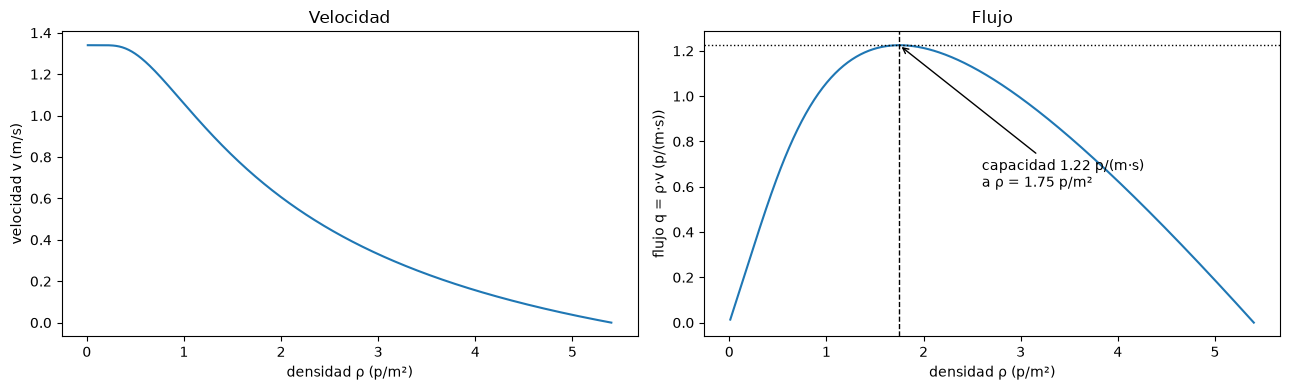

In [3]:
rho = np.linspace(0.01, RHO_MAX, 500)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(rho, weidmann(rho))
ax[0].set_xlabel("densidad ρ (p/m²)"); ax[0].set_ylabel("velocidad v (m/s)"); ax[0].set_title("Velocidad")
ax[1].plot(rho, rho * weidmann(rho))
ax[1].axvline(RHO_CAP, color="k", ls="--", lw=1)
ax[1].axhline(Q_MAX, color="k", ls=":", lw=1)
ax[1].annotate("capacidad %.2f p/(m·s)\na ρ = %.2f p/m²" % (Q_MAX, RHO_CAP), (RHO_CAP, Q_MAX),
               xytext=(2.6, 0.6), arrowprops=dict(arrowstyle="->"))
ax[1].set_xlabel("densidad ρ (p/m²)"); ax[1].set_ylabel("flujo q = ρ·v (p/(m·s))"); ax[1].set_title("Flujo")
plt.tight_layout()
plt.show()

## 2. Demanda y oferta (Godunov)

En cada paso, entre dos celdas vecinas pasa **el mínimo** entre:
- **Demanda** de la que manda: $\rho\,v(\rho)$ si está por debajo de la crítica; si está más llena, **la capacidad**.
- **Oferta** de la que recibe: la capacidad si está por debajo de la crítica; si está más llena, $\rho\,v(\rho)$, que tiende a 0 en el atasco.

**El destrabe:** con Weidmann solo, una celda muy llena manda $\rho\,v(\rho) \to 0$ y se queda atorada para siempre. Con Godunov pide la capacidad; si la de adelante tiene espacio, sale.

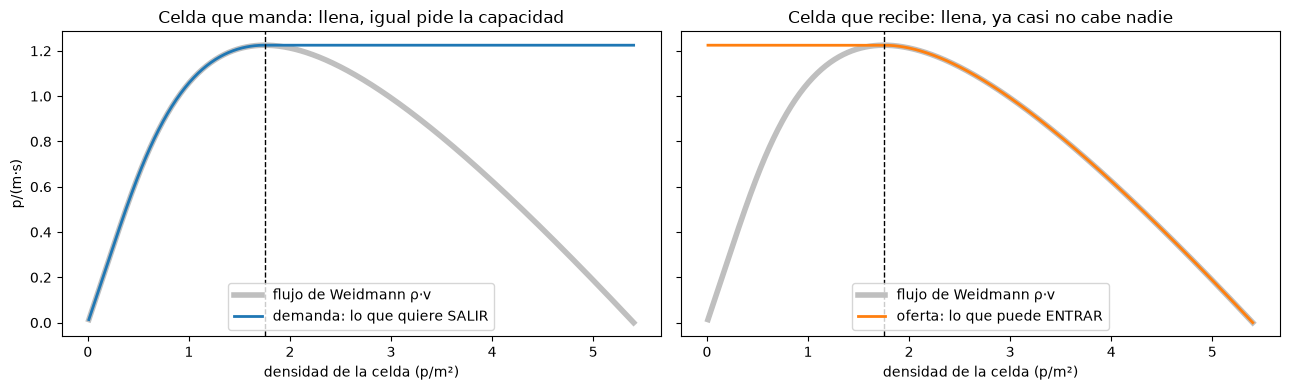

In [4]:
q = rho * weidmann(rho)
demanda = np.where(rho <= RHO_CAP, q, Q_MAX)
oferta = np.where(rho <= RHO_CAP, Q_MAX, q)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, curva, nombre, color in ((ax[0], demanda, "demanda: lo que quiere SALIR", "C0"),
                                (ax[1], oferta, "oferta: lo que puede ENTRAR", "C1")):
    a.plot(rho, q, color="0.75", lw=4, label="flujo de Weidmann ρ·v")
    a.plot(rho, curva, color=color, lw=2, label=nombre)
    a.axvline(RHO_CAP, color="k", ls="--", lw=1)
    a.set_xlabel("densidad de la celda (p/m²)")
    a.legend(loc="lower center")
ax[0].set_ylabel("p/(m·s)")
ax[0].set_title("Celda que manda: llena, igual pide la capacidad")
ax[1].set_title("Celda que recibe: llena, ya casi no cabe nadie")
plt.tight_layout()
plt.show()

## 3. Un paso de la simulación

Con el terreno $T$ (segundos a la salida, con la densidad de ahora):
1. Cada celda calcula su **demanda** y su **oferta**.
2. Reparte su demanda entre sus vecinas **cuesta abajo en $T$**, con peso $(\Delta T)^p$.
3. A la celda a la que le quieren meter más de lo que cabe, se le recorta a todas las que mandan, en la misma proporción (`factor`).
4. Se mueve la gente. Cada metro de puerta saca hasta $Q_{max}$ por segundo.

`paso_solo_weidmann` es lo mismo pero sin los pasos 1 y 3: lo usamos para comparar.

In [5]:
def mover(A, dy, dx, relleno=0.0):
    """Corre la matriz una celda: lo que estaba en [y, x] queda en [y+dy, x+dx]."""
    B = np.full_like(A, relleno)
    B[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = \
        A[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return B

DIRECCIONES = [(1, 0), (-1, 0), (0, 1), (0, -1)]   # (dy, dx): norte, sur, este, oeste

def caidas_hacia(T, p):
    """Cuánto baja T hacia cada vecina (0 si sube), elevado a p: el peso del reparto."""
    caidas = []
    for dy, dx in DIRECCIONES:
        Tv = mover(T, -dy, -dx, relleno=np.inf)       # T de la vecina, puesto en mi celda
        caida = np.zeros_like(T)
        ok = np.isfinite(T) & np.isfinite(Tv)
        caida[ok] = np.maximum(T[ok] - Tv[ok], 0)
        caidas.append(caida ** p)
    total = sum(caidas)
    total[total == 0] = np.inf                        # sin bajada: no manda nada
    return caidas, total

def paso(M, T, bloqueado, dt=0.3, p=3):
    """Un paso de Godunov: cada celda manda min(demanda, oferta) cuesta abajo en T."""
    q = M * weidmann(M)
    envia = np.where(M <= RHO_CAP, q, Q_MAX)          # demanda: lo que quiere salir
    recibe = np.where(M <= RHO_CAP, Q_MAX, q)         # oferta: lo que todavía cabe
    recibe[bloqueado] = 0
    caidas, total = caidas_hacia(T, p)
    quiere = [envia * dt * c / total for c in caidas]
    llega = sum(mover(f, dy, dx) for f, (dy, dx) in zip(quiere, DIRECCIONES))
    factor = np.minimum(1, recibe * dt / np.maximum(llega, 1e-12))   # lo que cabe / lo que llega
    nuevo = M.copy()
    for f, (dy, dx) in zip(quiere, DIRECCIONES):
        f = f * mover(factor, -dy, -dx)               # recortado por la oferta del destino
        nuevo -= f
        nuevo += mover(f, dy, dx)
    sale = np.where(salidas, np.minimum(nuevo, Q_MAX * dt), 0)   # cada metro de puerta saca hasta Q_MAX
    return nuevo - sale, sale.sum()

def paso_solo_weidmann(M, T, bloqueado, dt=0.3, p=3):
    """Lo mismo SIN demanda ni oferta: cada celda manda densidad × velocidad y la vecina
    lo recibe todo, quepa o no."""
    q = M * weidmann(M)
    caidas, total = caidas_hacia(T, p)
    nuevo = M.copy()
    for c, (dy, dx) in zip(caidas, DIRECCIONES):
        f = q * dt * c / total
        nuevo -= f
        nuevo += mover(f, dy, dx)
    sale = np.where(salidas, np.minimum(nuevo, Q_MAX * dt), 0)
    return nuevo - sale, sale.sum()

In [6]:
def simular(bloqueado, aforo=6000, dt=0.3, cada=8, p=3, regla=paso, t_max=900, cada_cuadro=5):
    """Evacuación completa. 'cada': cada cuántos pasos se recalcula T con la densidad."""
    M = np.where(~bloqueado, aforo / (~bloqueado).sum(), 0.0)   # gente repartida parejo
    fuera, t95 = 0.0, None
    cuadros, tiempos, dentro, pico = [], [], [], []
    for n in range(int(round(t_max / dt))):
        if n % cada == 0:
            T = campo(salidas, bloqueado, weidmann(M))      # el terreno se rehace con la densidad
        if n % cada_cuadro == 0:
            cuadros.append(M.copy())
            tiempos.append(n * dt)
        M, s = regla(M, T, bloqueado, dt, p)
        fuera += s
        dentro.append(M.sum())
        pico.append(M.max())
        if t95 is None and fuera >= 0.95 * aforo:
            t95 = (n + 1) * dt
        if M.sum() <= 0.005 * aforo:                       # queda menos del 0.5 %: evacuado
            break
    vacio = M.sum() <= 0.005 * aforo
    return {"t95": t95, "t_des": (n + 1) * dt if vacio else None, "M": M,
            "t": np.arange(1, len(dentro) + 1) * dt, "dentro": np.array(dentro), "pico": np.array(pico),
            "cuadros": cuadros, "tiempos": np.array(tiempos), "fuera": fuera, "aforo": aforo}

def cuadro_en(r, t):
    """La densidad guardada más cercana al tiempo t."""
    return r["cuadros"][int(np.argmin(np.abs(r["tiempos"] - t)))]

In [7]:
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, PowerNorm
from matplotlib.patches import Rectangle

mapa = LinearSegmentedColormap.from_list("densidad", [(0, "#d9d9d9"), (0.03, "#ffffcc"), (0.35, "#feb24c"),
                                                     (0.7, "#f03b20"), (1, "#800026")])
norma = PowerNorm(gamma=0.4, vmin=0, vmax=RHO_MAX)    # ** 0.4: que también se vea la densidad baja

def planta(ax, M, lay, titulo):
    """La densidad vista desde arriba, con muros, módulos y salidas."""
    im = ax.imshow(M, origin="lower", extent=(0, W, 0, H), cmap=mapa, norm=norma)
    ax.imshow(np.where(muros, 1.0, np.nan), origin="lower", extent=(0, W, 0, H), cmap="Greys", vmin=0, vmax=1.6)
    ax.imshow(np.where(salidas, 1.0, np.nan), origin="lower", extent=(0, W, 0, H), cmap=ListedColormap(["lime"]))
    for m in lay:
        ax.add_patch(Rectangle((m.x, m.y), m.ancho, m.fondo, facecolor=m.tipo.color, edgecolor="black", lw=0.6))
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])
    return im

t95 = 156.6 s (sale el 95 %) | t_des = 192.9 s (queda menos del 0.5 %) | densidad máxima 4.80 p/m²


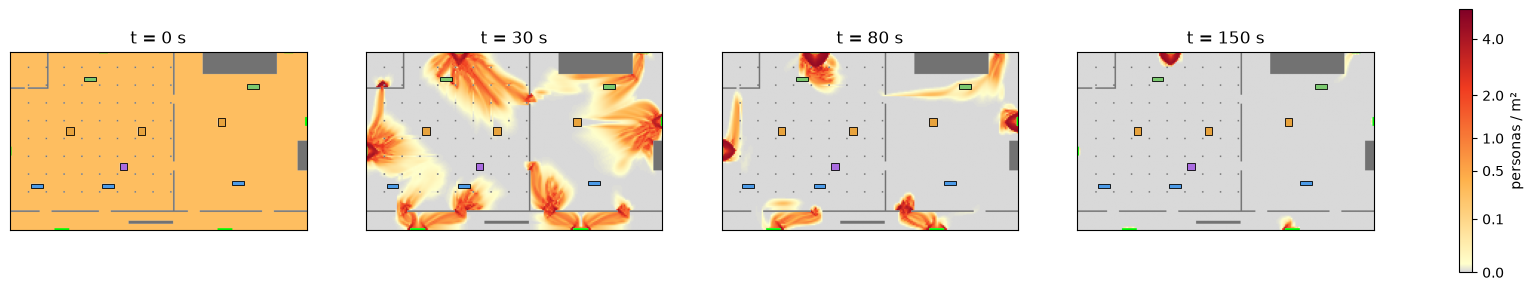

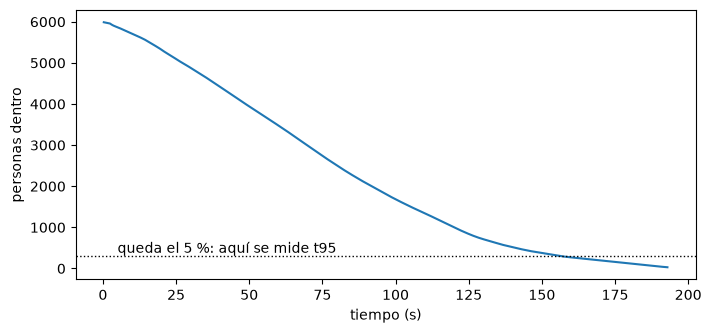

In [8]:
base = simular(ocupado)
print("t95 = %.1f s (sale el 95 %%) | t_des = %.1f s (queda menos del 0.5 %%) | densidad máxima %.2f p/m²"
      % (base["t95"], base["t_des"], base["pico"].max()))

fig, ax = plt.subplots(1, 4, figsize=(22, 3.8))
for a, t in zip(ax, (0, 30, 80, 150)):
    im = planta(a, cuadro_en(base, t), layout, "t = %d s" % t)
fig.colorbar(im, ax=ax, shrink=0.9, ticks=[0, 0.1, 0.5, 1, 2, 4], label="personas / m²")
plt.show()

plt.figure(figsize=(8, 3.5))
plt.plot(base["t"], base["dentro"])
plt.axhline(0.05 * base["aforo"], color="k", ls=":", lw=1)
plt.text(5, 0.05 * base["aforo"] + 80, "queda el 5 %: aquí se mide t95")
plt.xlabel("tiempo (s)"); plt.ylabel("personas dentro")
plt.show()

**Qué ver:** al inicio todo está parejo (0.27 p/m²). Luego se forman "ríos" hacia las salidas y filas frente a cada puerta. Al final quedan charcos donde la salida es angosta para la gente que le toca, como el cuarto de arriba a la izquierda, con su puerta de 2 m.

## 4. ¿Por qué Godunov? Lo que pasa con Weidmann solo

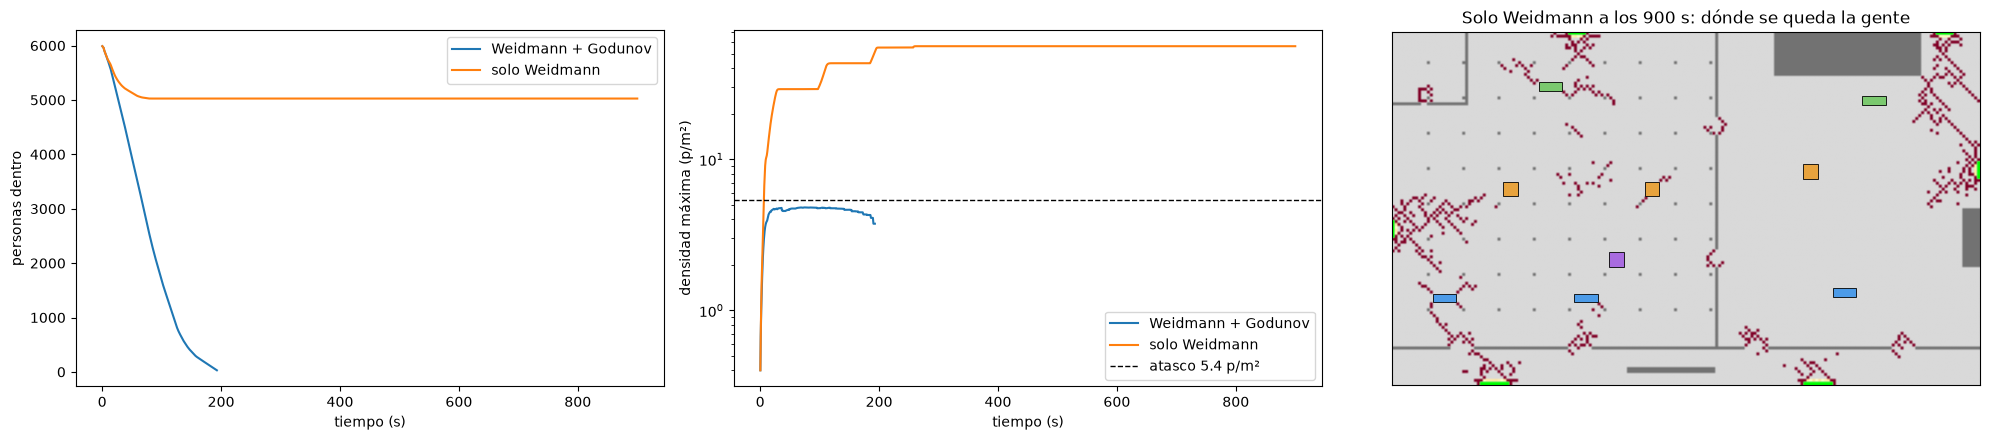

Con Godunov: evacúa en 193 s y la densidad nunca pasa de 4.80 p/m²
Solo Weidmann: a los 900 s siguen dentro 5026 personas, con celdas de hasta 56 p/m² (el atasco es 5.4)


In [9]:
solo = simular(ocupado, regla=paso_solo_weidmann)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.3))
ax[0].plot(base["t"], base["dentro"], label="Weidmann + Godunov")
ax[0].plot(solo["t"], solo["dentro"], label="solo Weidmann")
ax[0].set_xlabel("tiempo (s)"); ax[0].set_ylabel("personas dentro"); ax[0].legend()
ax[1].plot(base["t"], base["pico"], label="Weidmann + Godunov")
ax[1].plot(solo["t"], solo["pico"], label="solo Weidmann")
ax[1].axhline(RHO_MAX, color="k", ls="--", lw=1, label="atasco 5.4 p/m²")
ax[1].set_yscale("log"); ax[1].set_xlabel("tiempo (s)"); ax[1].set_ylabel("densidad máxima (p/m²)"); ax[1].legend()
planta(ax[2], solo["M"], layout, "Solo Weidmann a los %.0f s: dónde se queda la gente" % solo["t"][-1])
plt.tight_layout()
plt.show()
print("Con Godunov: evacúa en %.0f s y la densidad nunca pasa de %.2f p/m²" % (base["t_des"], base["pico"].max()))
print("Solo Weidmann: a los %.0f s siguen dentro %.0f personas, con celdas de hasta %.0f p/m² (el atasco es 5.4)"
      % (solo["t"][-1], solo["dentro"][-1], solo["pico"].max()))

Sin oferta, una celda recibe gente aunque ya no quepa: pasa de 5.4 p/m², Weidmann le da velocidad 0 y queda atorada para siempre. Con Godunov la densidad nunca pasa del atasco. Es el Teorema 2 de van Wageningen-Kessels et al. (2018), que se cumple mientras se respete la condición CFL (sección 6).

## 5. Hughes: ¿por qué recalcular $T$?

$T$ sale de la eikonal con la velocidad de Weidmann, así que **una zona llena cuesta más tiempo de cruzar**. Si se recalcula cada poco, la gente reacciona: rodea las multitudes y hasta cambia de salida. Es el modelo de Hughes (2002), con decisión *reactiva*: se decide con lo que se ve en ese momento.

Para verlo, la **cuenca** de cada salida: la zona cuya gente va a esa salida. Se compara al inicio y a los 40 s.

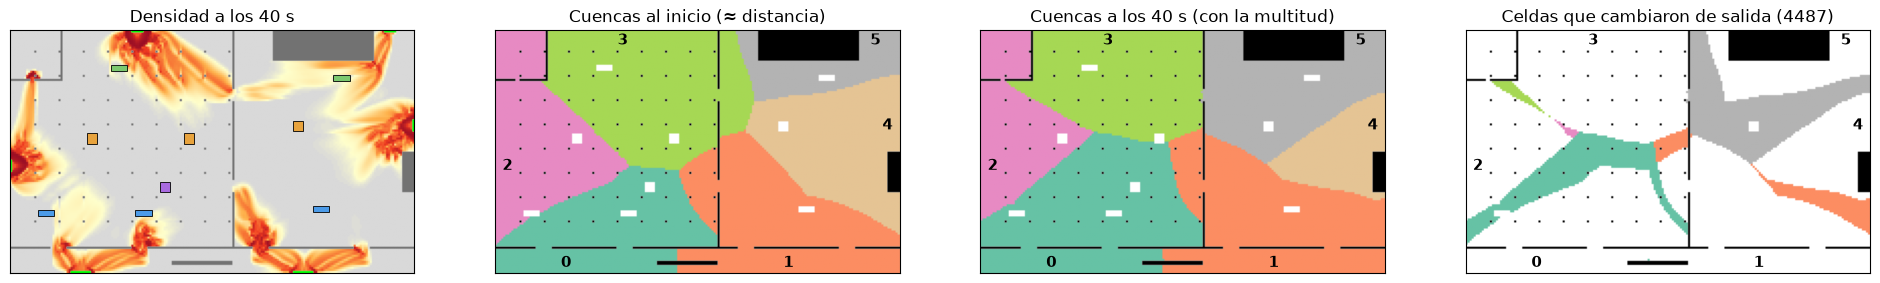

In [10]:
mascaras = []
for s in SALIDAS:
    m = np.zeros((H, W), dtype=bool)
    pintar(m, *s)
    mascaras.append(m)

def cuencas(M):
    """A qué salida va cada celda: la de menor T, con la velocidad que da la densidad M."""
    Ts = np.array([campo(m, ocupado, weidmann(M)) for m in mascaras])
    c = Ts.argmin(axis=0).astype(float)
    c[ocupado] = np.nan
    return c

c0 = cuencas(cuadro_en(base, 0))
c40 = cuencas(cuadro_en(base, 40))
cambio = np.where(c40 != c0, c40, np.nan)

colores_salida = plt.get_cmap("Set2", len(SALIDAS))
fig, ax = plt.subplots(1, 4, figsize=(24, 3.9))
planta(ax[0], cuadro_en(base, 40), layout, "Densidad a los 40 s")
for a, c, titulo in ((ax[1], c0, "Cuencas al inicio (≈ distancia)"), (ax[2], c40, "Cuencas a los 40 s (con la multitud)"),
                     (ax[3], cambio, "Celdas que cambiaron de salida (%d)" % np.isfinite(cambio).sum())):
    a.imshow(c, origin="lower", extent=(0, W, 0, H), cmap=colores_salida, vmin=-0.5, vmax=len(SALIDAS) - 0.5)
    a.imshow(np.where(muros, 1.0, np.nan), origin="lower", extent=(0, W, 0, H), cmap="Greys", vmin=0, vmax=1)
    for k, (x, y, w, f) in enumerate(SALIDAS):
        a.text(min(max(x + w / 2, 6), W - 6), min(max(y + f / 2, 5), H - 5), str(k), ha="center", va="center",
               fontsize=11, weight="bold")
    a.set_title(titulo); a.set_xticks([]); a.set_yticks([])
plt.show()

Y lo que eso cambia en el tiempo de evacuación, según cada cuánto se recalcula $T$ (`cada`, en pasos de 0.3 s):

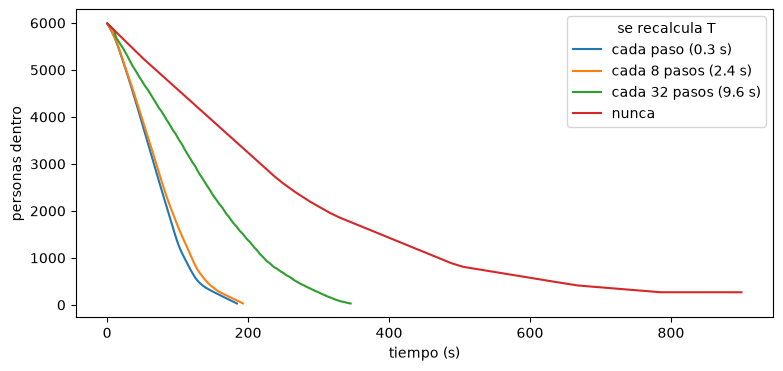

cada paso (0.3 s)      t95  147.9 s | densidad máxima 4.87
cada 8 pasos (2.4 s)   t95  156.6 s | densidad máxima 4.80
cada 32 pasos (9.6 s)  t95  295.2 s | densidad máxima 5.33
nunca                  t95  759.6 s | densidad máxima 5.40

Sin recalcular, la salida 3 (6 m) tendría que sacar sola a 1438 personas: al menos 196 s


In [11]:
variantes = {"cada paso (0.3 s)": 1, "cada 8 pasos (2.4 s)": 8, "cada 32 pasos (9.6 s)": 32, "nunca": 10**9}
res_cada = {nombre: (base if c == 8 else simular(ocupado, cada=c)) for nombre, c in variantes.items()}

plt.figure(figsize=(9, 4))
for nombre, r in res_cada.items():
    plt.plot(r["t"], r["dentro"], label=nombre)
plt.xlabel("tiempo (s)"); plt.ylabel("personas dentro"); plt.legend(title="se recalcula T")
plt.show()
for nombre, r in res_cada.items():
    print("%-22s t95 %6s s | densidad máxima %.2f" % (nombre, r["t95"] and "%.1f" % r["t95"], r["pico"].max()))

gente = [(c0 == k).sum() * cuadro_en(base, 0)[~ocupado].mean() for k in range(len(SALIDAS))]
k = int(np.argmax([g / (max(s[2], s[3]) * Q_MAX) for g, s in zip(gente, SALIDAS)]))
print("\nSin recalcular, la salida %d (%d m) tendría que sacar sola a %.0f personas: al menos %.0f s"
      % (k, max(SALIDAS[k][2], SALIDAS[k][3]), gente[k], gente[k] / (max(SALIDAS[k][2], SALIDAS[k][3]) * Q_MAX)))

**Qué ver:** si nunca se recalcula, cada salida tiene que vaciar ella sola su cuenca inicial, aunque otra esté libre. Además, sin reaccionar, la gente se apila hasta el atasco (5.4 p/m²), donde casi no se mueve. Recalcular cada 2.4 s (8 pasos) queda a un 6 % de hacerlo en cada paso, y cuesta 8 veces menos eikonales: es lo que usa el proyecto (`REFRESCO_CAMPO`).

## 6. Parámetros: qué pasa si se mueven

**El paso de tiempo $\Delta t$ y la condición CFL.** En 2D, van Wageningen-Kessels et al. (2018, Teorema 1) piden $v_0\,\Delta t \le \Delta x\,\Delta y / \sqrt{\Delta x^2 + \Delta y^2}$. Con celdas de 1 m, eso da $\Delta t \le 0.53$ s.

**El exponente $p$** del reparto entre vecinas. Es el único parámetro sin respaldo; el paper reparte con las componentes de la dirección de marcha.

In [12]:
cfl = 1 / (np.sqrt(2) * V0)
print("Δt máximo por CFL: %.3f s\n" % cfl)
print("%-10s %8s %8s %18s %18s" % ("", "t95 (s)", "t_des", "densidad máxima", "personas dentro*"))
for dt in (0.15, 0.3, 0.5, 0.8, 1.2):
    r = base if dt == 0.3 else simular(ocupado, dt=dt)
    print("Δt = %-5.2f %8s %8s %18.3g %18s %s" % (dt, r["t95"] and "%.1f" % r["t95"], r["t_des"] and "%.1f" % r["t_des"],
          r["pico"].max(), format(r["dentro"].max(), ",.0f"), "  ← viola la CFL" if dt > cfl else ""))
print()
for p in (1, 3, 6):
    r = base if p == 3 else simular(ocupado, p=p)
    print("p = %-6d %8.1f %8.1f %18.2f" % (p, r["t95"], r["t_des"], r["pico"].max()))
print("\n* el máximo de personas dentro en cualquier momento: si pasa de 6000, la simulación está creando gente")

Δt máximo por CFL: 0.528 s

            t95 (s)    t_des    densidad máxima   personas dentro*


Δt = 0.15     150.8    187.3               4.84              5,992 
Δt = 0.30     156.6    192.9                4.8              5,988 


Δt = 0.50     174.5    198.5               4.85              5,986 


Δt = 0.80     263.2    315.2               5.14              5,983   ← viola la CFL


Δt = 1.20      None     None           3.25e+10         83,426,595   ← viola la CFL



p = 1         175.2    219.0               4.92
p = 3         156.6    192.9               4.80


p = 6         160.8    196.5               4.87

* el máximo de personas dentro en cualquier momento: si pasa de 6000, la simulación está creando gente


**Qué ver:**
- Con $\Delta t$ dentro de la CFL los resultados se mueven poco (0.15 → 0.3 s: 4 %). Pasándose (0.8 s) los tiempos salen 70 % más largos, y con 1.2 s **explota**: una celda manda más gente de la que tiene, salen densidades negativas y se crea gente de la nada. Por eso el paper también topa la demanda con lo que hay en la celda (ec. 14).
- $p$ mueve el tiempo entre 157 y 175 s. No es enorme, pero el proyecto midió que el **orden** entre layouts sí es sensible a $p$. Por eso conviene cambiarlo por el reparto del paper.

## 7. ¿Cuánto es culpa del layout?

Aunque todos estuvieran pegados a las puertas, por 44 m de salida pasan a lo más $44 \times Q_{max}$ personas por segundo. Esa es la **cota**: lo mejor posible, y no depende del layout. La **eficiencia** = cota / t95 dice qué tanto de la capacidad de las salidas deja usar el layout.

Comparamos tu layout, el recinto vacío y un layout que pone módulos a 2 m de las salidas (eso lo prohíbe la restricción G4).

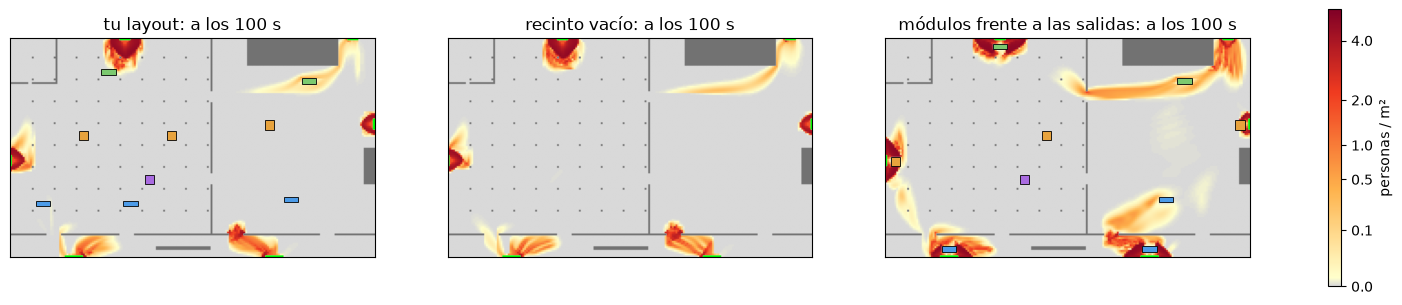

cota (95 %): 105.8 s

tu layout                      t95  156.6 s | eficiencia 0.68
recinto vacío                  t95  156.0 s | eficiencia 0.68
módulos frente a las salidas   t95  206.1 s | eficiencia 0.51


In [13]:
estorbo = [
    Modulo(Tipo.SANITARIO, 31, 3, 180),          # a 2 m de la salida sur principal
    Modulo(Tipo.SANITARIO, 141, 3, 180),         # a 2 m de la segunda salida sur
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 3, 50, 90),              # a 2 m de la salida oeste
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 192, 70, 270),           # a 2 m de la salida este
    Modulo(Tipo.BEBIDAS, 59, 114, 0),            # a 2 m de la salida norte de la sala A
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]
casos = {"tu layout": (layout, base), "recinto vacío": ([], simular(muros.copy())),
         "módulos frente a las salidas": (estorbo, simular(bloqueo(estorbo)))}
cota = 0.95 * 6000 / (salidas.sum() * Q_MAX)

fig, ax = plt.subplots(1, 3, figsize=(20, 4))
for a, (nombre, (lay, r)) in zip(ax, casos.items()):
    im = planta(a, cuadro_en(r, 100), lay, "%s: a los 100 s" % nombre)
fig.colorbar(im, ax=ax, shrink=0.9, ticks=[0, 0.1, 0.5, 1, 2, 4], label="personas / m²")
plt.show()

print("cota (95 %%): %.1f s\n" % cota)
for nombre, (lay, r) in casos.items():
    print("%-30s t95 %6.1f s | eficiencia %.2f" % (nombre, r["t95"], cota / r["t95"]))

**Qué ver:** en este recinto tus módulos ocupan el 1 % del área y están lejos de las salidas, así que dan lo mismo que el recinto vacío: ahí manda el ancho de las salidas. Pero en cuanto un módulo estorba la llegada a una salida, el tiempo sube un tercio. Eso es lo que $f_2$ castiga y lo que la restricción G4 prohíbe.

En el caso de prueba del proyecto (100 × 60 m, 9 módulos), donde los módulos sí pesan, el t95 de 1,206 layouts legales va de 60 a 131 s.

## Referencias

- Weidmann, U. (1993). *Transporttechnik der Fussgänger*. Schriftenreihe des IVT Nr. 90, ETH Zürich.
- Lebacque, J. P. (1996). The Godunov scheme and what it means for first order traffic flow models. *ISTTT 13*, 647–677.
- Hughes, R. L. (2002). A continuum theory for the flow of pedestrians. *Transportation Research Part B*, 36(6), 507–535.
- Huang, L. et al. (2009). Revisiting Hughes' dynamic continuum model for pedestrian flow and the development of an efficient solution algorithm. *Transportation Research Part B*, 43(1), 127–141.
- van Wageningen-Kessels, F., Daamen, W. y Hoogendoorn, S. P. (2018). Two-Dimensional Approximate Godunov Scheme and What It Means For Continuum Pedestrian Flow Models. *Transportation Science*, 52(3), 547–563.